In [204]:
from optiland import optic, physical_apertures
import optiland.backend as be
from optiland import analysis
from optiland import wavefront
from optiland.psf import MMDFTPSF, FFTPSF
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from torch.special import bessel_j1
from torch.special import bessel_j0
from scipy.special import j1
from scipy.special import jv
from dynesty import plotting as dyplot
from gluonts.torch.distributions import TruncatedNormal as truncnorm
import torch
from multiprocess.pool import Pool
from scipy.optimize import differential_evolution
from poppy.zernike import zernike_basis
plt.rcParams['figure.figsize'] = (20,10)
from nautilus import Sampler
import corner

In [205]:
be.set_backend("torch")
be.grad_mode.enable()
be.set_precision("float64")

In [206]:
torch.set_default_dtype(torch.float64)

In [6]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(torch.ceil((-1 + torch.sqrt(torch.tensor(1 + 8 * j))) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(torch.floor(torch.tensor(n / 2.)))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=64, rho=None, theta=None, outside=torch.nan, zero=6, **kwargs):
 
    if theta is None and rho is None:
        x = (torch.arange(npix, dtype=torch.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = torch.meshgrid(x, y)

        rho = torch.sqrt(xx ** 2 + yy ** 2)
        theta = torch.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not torch.all(torch.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*torch.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * jv(n+1, 2*torch.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * jv(n+1, 2*torch.pi*rho) * (1/rho) * torch.cos(torch.abs(torch.tensor(m) * theta))
    else:
        cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * jv(n+1, 2*torch.pi*rho) * (1/rho) * torch.sin(torch.abs(torch.tensor(m) * theta))
    return cb_result.detach().clone()


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in circbessel1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = torch.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output.detach().clone()

def decompose_psf(psf, nterms=10, basis=basis_vectors, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=0.0, **kwargs)
    basis_set = torch.tensor(basis_set)
    psf_flat = psf.ravel()
    basis_flat = basis_set.reshape(nterms, -1).to(torch.float64)
    numerators = torch.matmul(basis_flat, psf_flat)
    denominators = torch.einsum('ij,ij->i', basis_flat, basis_flat)
    coeffs = numerators / denominators
    return coeffs.detach().clone()

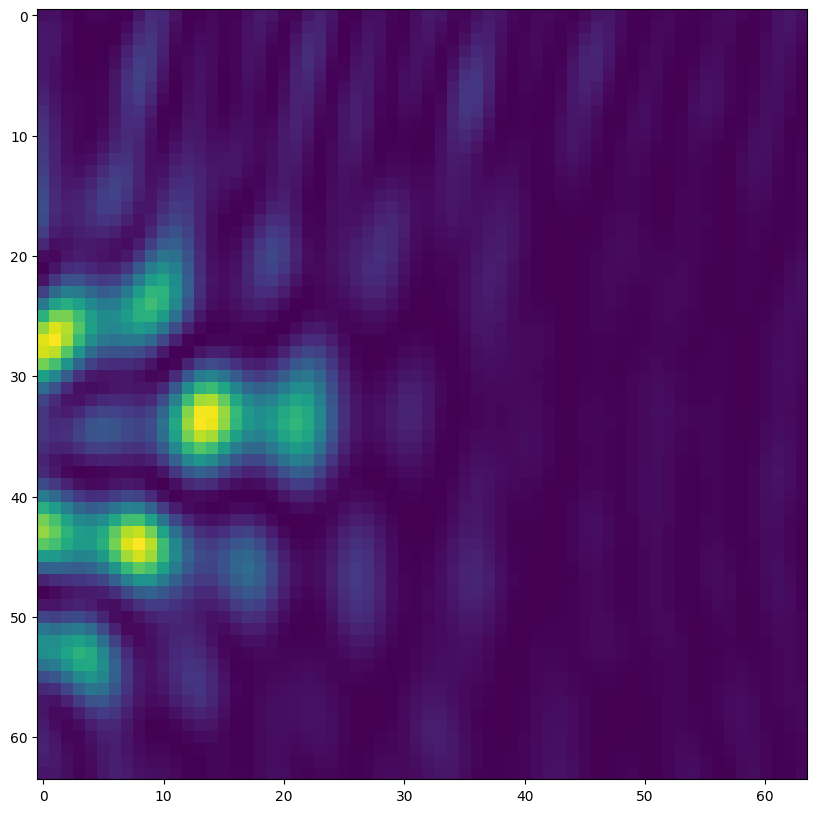

In [231]:
plt.imshow(MMDFTPSF(telescopeCreation(pdx=-117.79192158, pdy=-78.24263438, sdx=-745.0279596, sdy=-15.85729768), wavelength=0.65, field=(-0,-0)).psf[96:160,96:160].detach().numpy())

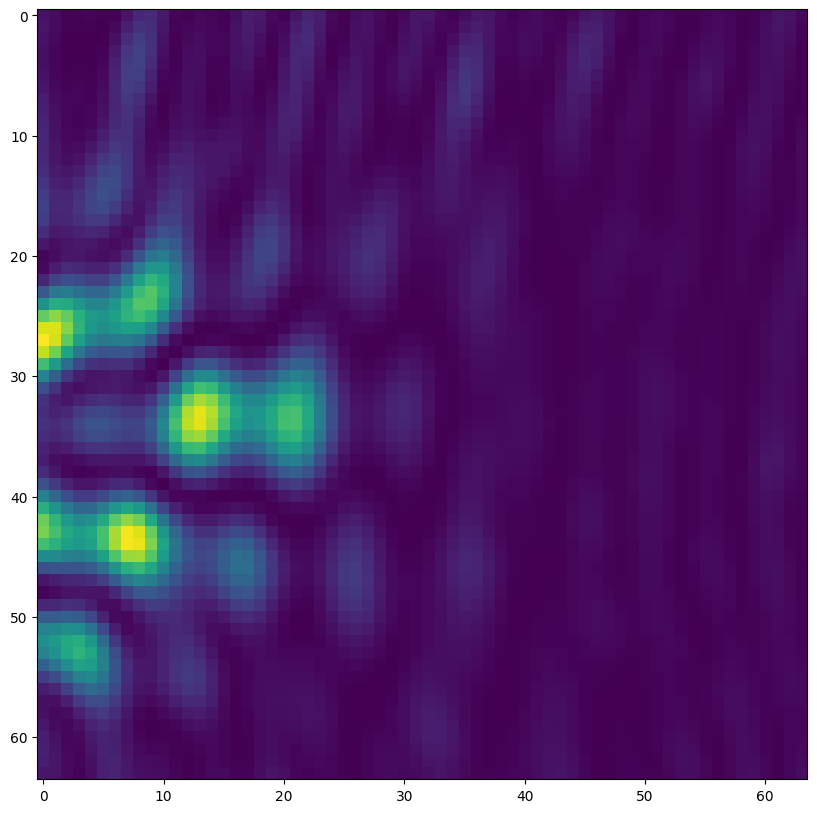

In [230]:
plt.imshow(MMDFTPSF(telescopeCreation(pdx=187.97154116 , pdy=-194.32444528 , sdx=-440.7907256, sdy=-139.5436858,), wavelength=0.65, field=(-0,-0)).psf[96:160,96:160].detach().numpy())

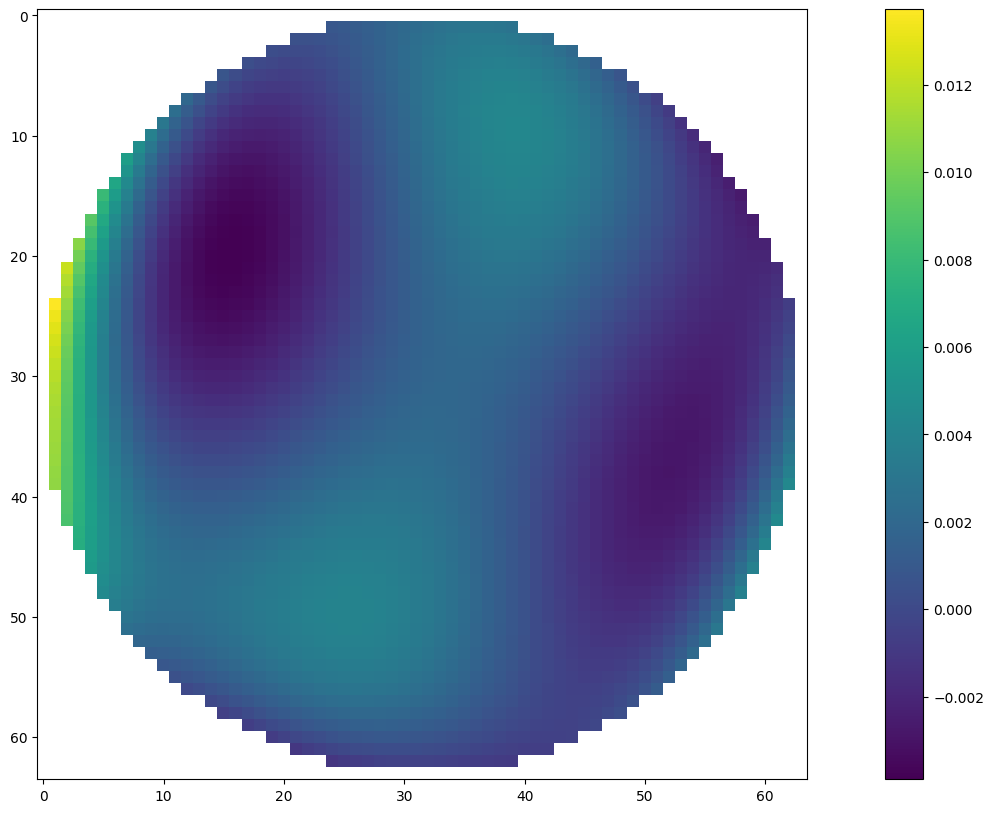

In [228]:
plt.imshow(np.sum(np.array(genpsf(pdx=-117.79192158, pdy=-78.24263438, sdx=-745.0279596, sdy=-15.85729768, dterms=15, field=(0,-0)).reshape(15,1,1)*zernike_basis(npix=64, nterms=15)), axis=0)-np.sum(np.array(genpsf(pdx=187.97154116 , pdy=-194.32444528 , sdx=-440.7907256, sdy=-139.5436858, dterms=15, field=(0,0)).reshape(15,1,1)*zernike_basis(npix=64, nterms=15)), axis=0))
plt.colorbar()

In [210]:
def telescopeCreation(WL=0.65,pdx=0,pdy=0,pdz=0,ptx=0,pty=0,sdx=0,sdy=0,sdz=0,stx=0,sty=0):

    K=1000 #mm to micron
    T = 3600
    #Pearl
    pearl = optic.Optic(name="Pearl")

    # set aperture
    pearl.set_aperture(aperture_type="EPD", value=6471.26)
    aperture1 = physical_apertures.RadialAperture(r_min=690, r_max=3210) 
    a1 = physical_apertures.PolygonAperture(x=[550, 3210, 3210, 550], y=[300, 300, -300, -300])
    a2 = physical_apertures.PolygonAperture(x=[-1735, -1475, 260, -260], y=[2705, 2855, 150, -150])
    a3 = physical_apertures.PolygonAperture(x=[-1735, -1475, 260, -260], y=[-2705, -2855, -150, 150])
    a = aperture1 - a1 - a2 - a3

    # set wavelengths
    pearl.add_wavelength(value=WL)

    # add surfaces
    pearl.add_surface(index=0, radius=be.inf, thickness=be.inf)

    pearl.add_surface(
        index=1,
        radius=-16256,
        thickness=-7400.005+pdz/K,
        dx=pdx/K,
        dy=pdy/K,
        rx=ptx/T,
        ry=pty/T,
        conic=-0.9953569,
        material="mirror",
        aperture=a,
        is_stop=True
    )
    pearl.add_surface(
        index=2,
        radius=-1660.575,
        thickness=7449.97+sdz/K,
        dx=sdx/K,
        dy=sdy/K,
        rx=stx/T,
        ry=sty/T,
        conic=-1.566503,
        material="mirror",
        #aperture=aperture2
    )
    pearl.add_surface(
        index=3,
        radius=-1830.517,
        thickness=-1033.62,
        conic=-0.718069,
        material="mirror",

    )

    pearl.add_surface(
        index=4,
        radius=be.inf,
        thickness=1220.34,
        material="mirror",

    )

    pearl.add_surface(index=5)
    pearl.set_field_type(field_type="angle")
    pearl.add_field(y=0.)
    pearl.add_field(y=0.115)
    pearl.add_field(y=-0.115)

    return pearl

In [234]:
def genpsf(WL=0.650, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field = (0,0)):

    telescope = telescopeCreation(WL, pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, grid_size=64)
    PSF = psf.psf[96:160,96:160]
    r = decompose_psf(PSF, nterms=dterms, basis=zernike_basis)

    return r

In [66]:
xcy = []

for i in range(10000):
    px = np.round(np.random.normal(loc=0,scale=400), 2)
    py = np.round(np.random.normal(loc=0,scale=400), 2)
    sx = np.round(np.random.normal(loc=0,scale=1250), 2)
    sy = np.round(np.random.normal(loc=0,scale=1250), 2)
    ars = genpsf(WL=0.65, pdx=px, pdy=py, sdx=sx, sdy=sy, dterms=11, field=(1,1))
    ars = np.array(ars.tolist()).T
    xcy.append(ars)

In [67]:
xcy = torch.tensor(xcy)

In [68]:
torch.cov(xcy.T)

tensor([[ 3.7891e-03, -6.0436e-05, -2.9689e-04, -1.9568e-03,  1.0552e-04,
          1.0664e-04,  9.2941e-05, -3.5203e-05,  2.9821e-05,  2.8061e-05,
          7.2534e-04],
        [-6.0436e-05,  2.2482e-03,  9.3991e-05, -6.5446e-06, -5.8809e-05,
          9.9458e-06, -2.7672e-05, -1.3159e-03,  4.9227e-05,  4.7765e-05,
          5.6951e-05],
        [-2.9689e-04,  9.3991e-05,  2.0525e-03,  4.5192e-05, -4.6275e-05,
          1.8574e-04, -1.1950e-03, -2.6979e-05,  1.8893e-05, -3.9461e-05,
          5.6153e-05],
        [-1.9568e-03, -6.5446e-06,  4.5192e-05,  1.8584e-03, -9.4033e-06,
         -3.7168e-05,  6.9090e-05,  1.4209e-04,  2.5998e-06, -1.0343e-05,
         -1.0932e-03],
        [ 1.0552e-04, -5.8809e-05, -4.6275e-05, -9.4033e-06,  7.8971e-04,
          1.4480e-05,  4.4169e-05,  3.6693e-05,  2.1654e-05,  4.7509e-05,
         -2.0534e-05],
        [ 1.0664e-04,  9.9458e-06,  1.8574e-04, -3.7168e-05,  1.4480e-05,
          8.9440e-04, -1.0671e-04, -2.8599e-06, -3.0215e-05, -1.3475e-0

In [330]:
#Truth

pdx_true = torch.normal(mean=torch.tensor(0, dtype=torch.float64),std=torch.tensor(400, dtype=torch.float64))
pdy_true = torch.normal(mean=torch.tensor(0, dtype=torch.float64),std=torch.tensor(400, dtype=torch.float64))
sdx_true = torch.normal(mean=torch.tensor(0, dtype=torch.float64),std=torch.tensor(1250, dtype=torch.float64))
sdy_true = torch.normal(mean=torch.tensor(0, dtype=torch.float64),std=torch.tensor(1250, dtype=torch.float64))

## PSF
ct = genpsf(WL=0.65, pdx=pdx_true, pdy=pdy_true, sdx=sdx_true, sdy=sdy_true, dterms=11)
ctf10 = genpsf(WL=0.65, pdx=pdx_true, pdy=pdy_true, sdx=sdx_true, sdy=sdy_true, dterms=11, field=(1,0))
ctf01 = genpsf(WL=0.65, pdx=pdx_true, pdy=pdy_true, sdx=sdx_true, sdy=sdy_true, dterms=11, field=(0,1))
ctf11 = genpsf(WL=0.65, pdx=pdx_true, pdy=pdy_true, sdx=sdx_true, sdy=sdy_true, dterms=11, field=(1,1))

print(f"{pdx_true},\n {pdy_true},\n {sdx_true},\n {sdy_true}")


-564.3625621724862,
 59.291646028614295,
 386.2592290677595,
 478.34551574030405


In [187]:
C = torch.tensor([[ 3.9786e-03, -5.2813e-05, -5.7611e-05, -2.2356e-03,  1.6534e-04,
          1.2929e-04,  7.4311e-05, -7.2246e-05, -5.8427e-05,  3.2279e-05,
          1.0622e-03],
        [-5.2813e-05,  2.3330e-03,  1.5852e-04, -3.6226e-05, -7.2404e-05,
          1.3049e-05, -1.0310e-04, -1.2882e-03,  1.5916e-05,  5.9101e-05,
          2.7002e-05],
        [-5.7611e-05,  1.5852e-04,  2.0822e-03,  6.4318e-05, -6.9988e-05,
         -7.5875e-05, -1.2448e-03, -9.9462e-05,  2.6464e-05, -7.6616e-05,
         -7.9057e-05],
        [-2.2356e-03, -3.6226e-05,  6.4318e-05,  2.4014e-03, -5.3135e-05,
          1.3063e-05, -1.2512e-04,  1.3110e-04,  3.9735e-06, -1.5941e-05,
         -1.6736e-03],
        [ 1.6534e-04, -7.2404e-05, -6.9988e-05, -5.3135e-05,  8.2853e-04,
         -3.7755e-05,  4.2826e-05,  2.1627e-05,  2.4475e-05, -3.5851e-05,
          9.2615e-06],
        [ 1.2929e-04,  1.3049e-05, -7.5875e-05,  1.3063e-05, -3.7755e-05,
          9.4116e-04,  2.6980e-05, -2.7631e-05, -1.0195e-05, -3.5214e-05,
         -2.3510e-05],
        [ 7.4311e-05, -1.0310e-04, -1.2448e-03, -1.2512e-04,  4.2826e-05,
          2.6980e-05,  1.2092e-03,  1.0181e-04, -3.2224e-06,  4.1211e-05,
          1.3515e-04],
        [-7.2246e-05, -1.2882e-03, -9.9462e-05,  1.3110e-04,  2.1627e-05,
         -2.7631e-05,  1.0181e-04,  1.1582e-03, -8.5763e-06, -1.3398e-05,
         -7.4954e-05],
        [-5.8427e-05,  1.5916e-05,  2.6464e-05,  3.9735e-06,  2.4475e-05,
         -1.0195e-05, -3.2224e-06, -8.5763e-06,  2.6742e-04,  2.8461e-06,
          7.1635e-06],
        [ 3.2279e-05,  5.9101e-05, -7.6616e-05, -1.5941e-05, -3.5851e-05,
         -3.5214e-05,  4.1211e-05, -1.3398e-05,  2.8461e-06,  2.3168e-04,
          8.1127e-08],
        [ 1.0622e-03,  2.7002e-05, -7.9057e-05, -1.6736e-03,  9.2615e-06,
         -2.3510e-05,  1.3515e-04, -7.4954e-05,  7.1635e-06,  8.1127e-08,
          1.5019e-03]])

Cf10 = torch.tensor([[ 3.4516e-03, -1.0049e-04,  2.5870e-04, -1.6749e-03,  7.8920e-05,
         -2.3221e-04, -3.6411e-04,  1.3434e-04, -5.7900e-05, -9.9283e-05,
          5.8937e-04],
        [-1.0049e-04,  1.8406e-03,  8.7148e-05,  1.0266e-04, -3.4118e-05,
         -6.4488e-05, -3.0251e-06, -9.7890e-04,  4.1259e-05, -5.8443e-05,
         -8.3925e-05],
        [ 2.5870e-04,  8.7148e-05,  2.2410e-03, -2.2259e-04,  1.9850e-05,
         -1.5810e-04, -1.2895e-03, -9.5372e-06, -8.3532e-05, -1.5110e-05,
          9.9018e-05],
        [-1.6749e-03,  1.0266e-04, -2.2259e-04,  1.5831e-03,  2.1058e-05,
          1.0635e-04,  3.6565e-04, -1.8321e-04, -4.0755e-05,  5.8697e-05,
         -8.9792e-04],
        [ 7.8920e-05, -3.4118e-05,  1.9850e-05,  2.1058e-05,  7.5728e-04,
          1.1197e-05, -7.9921e-06, -7.2211e-05,  2.3545e-05, -6.2657e-06,
         -4.5748e-05],
        [-2.3221e-04, -6.4488e-05, -1.5810e-04,  1.0635e-04,  1.1197e-05,
          8.6340e-04,  4.8940e-05,  4.3579e-05,  4.1250e-05, -2.7301e-05,
         -3.1952e-05],
        [-3.6411e-04, -3.0251e-06, -1.2895e-03,  3.6565e-04, -7.9921e-06,
          4.8940e-05,  1.1801e-03, -6.3564e-05,  3.7644e-05, -5.2461e-06,
         -1.8634e-04],
        [ 1.3434e-04, -9.7890e-04, -9.5372e-06, -1.8321e-04, -7.2211e-05,
          4.3579e-05, -6.3564e-05,  8.2623e-04, -3.2852e-05,  5.1590e-05,
          1.4080e-04],
        [-5.7900e-05,  4.1259e-05, -8.3532e-05, -4.0755e-05,  2.3545e-05,
          4.1250e-05,  3.7644e-05, -3.2852e-05,  2.2696e-04, -8.3494e-06,
          3.5865e-05],
        [-9.9283e-05, -5.8443e-05, -1.5110e-05,  5.8697e-05, -6.2657e-06,
         -2.7301e-05, -5.2461e-06,  5.1590e-05, -8.3494e-06,  2.3132e-04,
         -1.7737e-05],
        [ 5.8937e-04, -8.3925e-05,  9.9018e-05, -8.9792e-04, -4.5748e-05,
         -3.1952e-05, -1.8634e-04,  1.4080e-04,  3.5865e-05, -1.7737e-05,
          6.7462e-04]])

Cf01 = torch.tensor([[ 3.8130e-03,  3.5479e-04,  7.1479e-05, -1.7643e-03,  5.5957e-05,
          1.0870e-04, -1.3657e-04, -9.7017e-05,  1.5122e-05, -1.5149e-05,
          6.3443e-04],
        [ 3.5479e-04,  2.3684e-03,  4.5693e-05,  2.7448e-05,  1.2547e-05,
          2.1109e-04, -3.4242e-05, -1.2768e-03,  1.9355e-05,  5.0378e-05,
         -1.2580e-04],
        [ 7.1479e-05,  4.5693e-05,  2.2220e-03, -7.8055e-05,  1.4186e-04,
         -1.3276e-05, -1.1771e-03, -3.7642e-05,  3.2316e-05, -3.2672e-05,
         -1.6567e-05],
        [-1.7643e-03,  2.7448e-05, -7.8055e-05,  1.6818e-03, -1.9940e-05,
         -4.6961e-05,  7.2452e-05, -8.9196e-05, -2.3935e-05,  5.0850e-05,
         -1.0447e-03],
        [ 5.5957e-05,  1.2547e-05,  1.4186e-04, -1.9940e-05,  8.8575e-04,
         -7.0030e-07, -6.8197e-05, -4.7029e-05,  1.1274e-04,  1.7067e-05,
         -5.8934e-06],
        [ 1.0870e-04,  2.1109e-04, -1.3276e-05, -4.6961e-05, -7.0030e-07,
          9.6347e-04,  1.2478e-05, -6.6438e-05,  3.9174e-05,  2.6589e-05,
         -5.4375e-06],
        [-1.3657e-04, -3.4242e-05, -1.1771e-03,  7.2452e-05, -6.8197e-05,
          1.2478e-05,  9.9395e-04,  3.8594e-05, -4.7664e-06,  2.8126e-05,
          6.3678e-05],
        [-9.7017e-05, -1.2768e-03, -3.7642e-05, -8.9196e-05, -4.7029e-05,
         -6.6438e-05,  3.8594e-05,  1.0023e-03, -9.1127e-06, -5.4099e-05,
          1.2547e-04],
        [ 1.5122e-05,  1.9355e-05,  3.2316e-05, -2.3935e-05,  1.1274e-04,
          3.9174e-05, -4.7664e-06, -9.1127e-06,  2.4443e-04, -2.4892e-05,
          1.8233e-05],
        [-1.5149e-05,  5.0378e-05, -3.2672e-05,  5.0850e-05,  1.7067e-05,
          2.6589e-05,  2.8126e-05, -5.4099e-05, -2.4892e-05,  2.7545e-04,
         -4.1003e-05],
        [ 6.3443e-04, -1.2580e-04, -1.6567e-05, -1.0447e-03, -5.8934e-06,
         -5.4375e-06,  6.3678e-05,  1.2547e-04,  1.8233e-05, -4.1003e-05,
          8.6695e-04]])

Cf11 = torch.tensor([[ 3.7891e-03, -6.0436e-05, -2.9689e-04, -1.9568e-03,  1.0552e-04,
          1.0664e-04,  9.2941e-05, -3.5203e-05,  2.9821e-05,  2.8061e-05,
          7.2534e-04],
        [-6.0436e-05,  2.2482e-03,  9.3991e-05, -6.5446e-06, -5.8809e-05,
          9.9458e-06, -2.7672e-05, -1.3159e-03,  4.9227e-05,  4.7765e-05,
          5.6951e-05],
        [-2.9689e-04,  9.3991e-05,  2.0525e-03,  4.5192e-05, -4.6275e-05,
          1.8574e-04, -1.1950e-03, -2.6979e-05,  1.8893e-05, -3.9461e-05,
          5.6153e-05],
        [-1.9568e-03, -6.5446e-06,  4.5192e-05,  1.8584e-03, -9.4033e-06,
         -3.7168e-05,  6.9090e-05,  1.4209e-04,  2.5998e-06, -1.0343e-05,
         -1.0932e-03],
        [ 1.0552e-04, -5.8809e-05, -4.6275e-05, -9.4033e-06,  7.8971e-04,
          1.4480e-05,  4.4169e-05,  3.6693e-05,  2.1654e-05,  4.7509e-05,
         -2.0534e-05],
        [ 1.0664e-04,  9.9458e-06,  1.8574e-04, -3.7168e-05,  1.4480e-05,
          8.9440e-04, -1.0671e-04, -2.8599e-06, -3.0215e-05, -1.3475e-05,
          1.2276e-05],
        [ 9.2941e-05, -2.7672e-05, -1.1950e-03,  6.9090e-05,  4.4169e-05,
         -1.0671e-04,  1.0633e-03, -1.6368e-05, -8.7127e-06,  3.7482e-05,
         -1.1577e-04],
        [-3.5203e-05, -1.3159e-03, -2.6979e-05,  1.4209e-04,  3.6693e-05,
         -2.8599e-06, -1.6368e-05,  1.1808e-03, -1.3702e-05, -2.8609e-05,
         -1.7400e-04],
        [ 2.9821e-05,  4.9227e-05,  1.8893e-05,  2.5998e-06,  2.1654e-05,
         -3.0215e-05, -8.7127e-06, -1.3702e-05,  2.3716e-04,  9.5898e-06,
         -6.8156e-06],
        [ 2.8061e-05,  4.7765e-05, -3.9461e-05, -1.0343e-05,  4.7509e-05,
         -1.3475e-05,  3.7482e-05, -2.8609e-05,  9.5898e-06,  2.3104e-04,
         -2.1624e-06],
        [ 7.2534e-04,  5.6951e-05,  5.6153e-05, -1.0932e-03, -2.0534e-05,
          1.2276e-05, -1.1577e-04, -1.7400e-04, -6.8156e-06, -2.1624e-06,
          8.5195e-04]])


Cinv = torch.linalg.inv(C).to(torch.float64)  # precision matrix
Cf10inv = torch.linalg.inv(Cf10).to(torch.float64)
Cf01inv = torch.linalg.inv(Cf01).to(torch.float64)
Cf11inv = torch.linalg.inv(Cf11).to(torch.float64)
lnorm = -0.5 * (torch.log(torch.tensor(2*torch.pi)) * 4 + torch.log(torch.linalg.det(C)))  # ln(normalization)
lnormf10 = -0.5 * (torch.log(torch.tensor(2*torch.pi)) * 4 + torch.log(torch.linalg.det(Cf10))) 
lnormf01 = -0.5 * (torch.log(torch.tensor(2*torch.pi)) * 4 + torch.log(torch.linalg.det(Cf01))) 
lnormf11 = -0.5 * (torch.log(torch.tensor(2*torch.pi)) * 4 + torch.log(torch.linalg.det(Cf11))) 

# log-likelihood
def loglike(theta):
    lpdx,lpdy,lsdx,lsdy = theta
    ## PSF
    c = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, sdx=lsdx, sdy=lsdy, dterms=11)
    cf10 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, sdx=lsdx, sdy=lsdy, dterms=11, field=(1,0))
    cf01 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, sdx=lsdx, sdy=lsdy, dterms=11, field=(0,1))
    cf11 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, sdx=lsdx, sdy=lsdy, dterms=11, field=(1,1))
    
    return -0.5 * torch.matmul(c-ct, torch.matmul(Cinv, c-ct)) + lnorm -0.5 * torch.matmul(cf10-ctf10, torch.matmul(Cf10inv, cf10-ctf10)) + lnormf10 -0.5 * torch.matmul(cf01-ctf01, torch.matmul(Cf01inv, cf01-ctf01)) + lnormf01 -0.5 * torch.matmul(cf11-ctf11, torch.matmul(Cf11inv, cf11-ctf11)) + lnormf11

# prior transform
def ptform(utheta):

    upx,upy,usx,usy = utheta

    xpx =  800. * (2. * upx - 1.)
    xpy =  800. * (2. * upy - 1.)
    xsx =  2500. * (2. * usx - 1.)
    xsy =  2500. * (2. * usy - 1.)

    """mpx, spx = torch.tensor(0), torch.tensor(16)  # mean and standard deviation
    lpx, hpx = torch.tensor(-50), torch.tensor(50)  # lower and upper bounds
    xpx = truncnorm(min=lpx, max=hpx, loc=mpx, scale=spx).icdf(torch.tensor(upx))

    mpy, spy = torch.tensor(0), torch.tensor(16)  # mean and standard deviation
    lpy, hpy = torch.tensor(-50), torch.tensor(50)  # lower and upper bounds
    xpy = truncnorm(min=lpy, max=hpy, loc=mpy, scale=spy).icdf(torch.tensor(upy))

    msx, ssx = torch.tensor(0), torch.tensor(16)  # mean and standard deviation
    lsx, hsx = torch.tensor(-50), torch.tensor(50)  # lower and upper bounds
    xsx = truncnorm(min=lsx, max=hsx, loc=msx, scale=ssx).icdf(torch.tensor(usx))

    msy, ssy = torch.tensor(0), torch.tensor(16)  # mean and standard deviation
    lsy, hsy = torch.tensor(-50), torch.tensor(50)  # lower and upper bounds
    xsy = truncnorm(min=lsy, max=hsy, loc=msy, scale=ssy).icdf(torch.tensor(usy))"""

    return xpx,xpy,xsx,xsy

Static nested sampling

// Initialize live points.
Draw K “live” points{1, . . . , K } from the prior π().
// Main sampling loop.
while stopping criterion not met do
Compute the minimum likelihood Lmin among thecurrent set of live points.
Add the kth live point k associated with Lmin to a list of “dead” points.
Sample a new point ′ from the prior subject to the constraintL(′) ≥ Lmin .
Replace k with ′.
// Check whether to stop.
Evaluate stopping criterion.
end
// Add final live points.
while K > 0 do
Compute the minimum likelihood Lmin among thecurrent set of live points.
Add the kth live point k associated with Lmin to a list of “dead” points.
Remove k from the set of live points.
Set K = K − 1.
end

In [99]:
import warnings
warnings.filterwarnings('ignore')

In [217]:
def Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=5, K = 500, iter=1000):
    stopping_criterion = 10E-5#+10E-3*(K-1)
    dps = []
    ls = [] 
    PVAL = 1
    Z = 0
    lps_init = torch.rand(ndim, K)
    lps = prior(lps_init)
    lps = torch.stack(list(lps), dim=0)
    lps = lps.transpose(-1,0)
    lps_eval = torch.zeros(K)
    pbar1 = tqdm(total = K)
    for i in range(K):
        lps_eval[i] = loglike(lps[i])
        pbar1.update(1)
    pbar1.close()
    
    minl = torch.min(lps_eval, 0)[0]
    n_it = 1
    dlogz = 0.1

    pbar2 = tqdm(total = n_it+1)
    while n_it < iter+1:
        minl = torch.min(lps_eval, 0)[0]
        maxl = torch.max(lps_eval, 0)[0]
        dp1 = lps[torch.min(lps_eval, 0)[1]]
        nlp = prior(torch.rand(ndim,1))
        nlp = torch.stack(list(nlp), dim=0)
        nlike = likelihood(nlp)
        #z = (minl)*(-1/K)
        if nlike > minl:
            dps.append(dp1)
            ls.append(minl)
            lps = lps[lps!=dp1]
            lps = lps.reshape(K-1, ndim)
            lps_eval = lps_eval[lps_eval!=minl]
            nlp = nlp.reshape(1, ndim)
            lps = torch.cat((lps, nlp))
            nlike = nlike.reshape(1)
            lps_eval = torch.cat((lps_eval, nlike))
            dz = PVAL*torch.max(lps_eval)
            PVAL -= K/(K+1)
            #wi = (torch.exp(torch.tensor(-(n_it-1)/K))-torch.exp(torch.tensor(-(n_it+1)/K)))/2
            Z += dz
            dlogz = torch.log(Z + dz) - torch.log(Z)
            pbar2.update(1)
            pbar2.set_postfix({'dlogz': dlogz, 'logl': maxl})
            #print(f"dlogz = {dlogz}, niter = {n_it}")
            n_it += 1 
           
    for n_it in range(n_it,n_it+K-1):
        minl = torch.min(lps_eval, 0)[0]
        dp1 = lps[torch.min(lps_eval, 0)[1]]
        dps.append(dp1)
        ls.append(minl)
        lps = lps[lps!=dp1]
        lps = lps.reshape(K-1, ndim)
        lps_eval = lps_eval[lps_eval!=minl]
        #dz = PVAL*torch.max(lps_eval)
        #PVAL = PVAL - 1/K
        #z = (minl)*(-1/K)
        #dlogz = torch.log(z + dz) - torch.log(z)
        #print(f"dp1 = {dp1}")
        pbar2.update(1)
        #print(f"minl = {minl}, n_it = {n_it}")
        K = K-1
        n_it += 1
    pbar2.close() 

    return dps, ls

In [331]:
loglike([pdx_true, pdy_true, sdx_true, sdy_true])

tensor(146.5958)

In [332]:
print([pdx_true, pdy_true, sdx_true, sdy_true])

[tensor(-564.3626), tensor(59.2916), tensor(386.2592), tensor(478.3455)]


In [333]:
sampler = Sampler(ptform, loglike, n_dim=4)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 11     | 2        | 4        | 46200    | N/A    | 10042 | +142.28  


np.True_

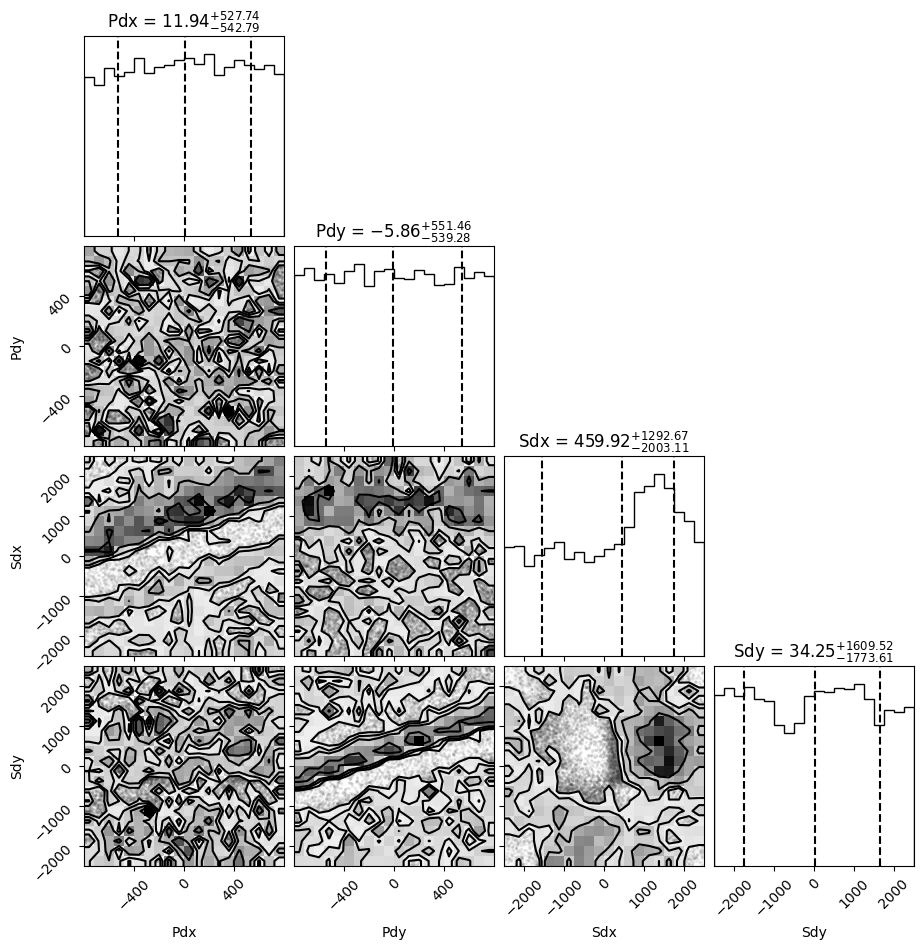

In [334]:
points, log_w, log_l = sampler.posterior()
figure = corner.corner(
    points, weights=np.exp(log_w), labels=['Pdx', 'Pdy', 'Sdx', 'Sdy'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,)

In [335]:
x0 = [(np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]

In [336]:
print(x0)

[(array(50.72232615), array(-67.23372342), array(1044.18704589), array(347.44054521))]


In [337]:
print(f"{pdx_true},\n {pdy_true},\n {sdx_true},\n {sdy_true}")

-564.3625621724862,
 59.291646028614295,
 386.2592290677595,
 478.34551574030405


In [338]:
bounds = [(np.quantile(points[-100:,0], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,0], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,1], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,1], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,2], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,2], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,3], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,3], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]

In [339]:
bounds

[(array(-772.90106987), array(745.04400262)),
 (array(-762.58794464), array(759.70196199)),
 (array(176.01814784), array(1775.57699938)),
 (array(-388.62634677), array(1177.60567876))]

In [340]:
def my_callback(intermediate_result):
    # intermediate_result is an OptimizeResult object
    with open("solutions_log.txt", "a") as f:
        f.write(f"Objective: {intermediate_result.fun}, Best X: {intermediate_result.x}\n")
    if intermediate_result.fun <= 1e-11:
        print(f"Terminating: reached objective value {intermediate_result.fun}")
        return True  # Returns True to halt optimization
    return False

In [341]:
def lstep(t):
      return np.sum(np.array(ct - genpsf(WL=0.65, pdx=t[0], pdy=t[1], sdx=t[2], sdy=t[3], dterms=11))**2 + np.array(ctf10 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], sdx=t[2], sdy=t[3], dterms=11, field=(1,0)))**2 + np.array(ctf01 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], sdx=t[2], sdy=t[3], dterms=11, field=(0,1)))**2 + np.array(ctf11 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], sdx=t[2], sdy=t[3], dterms=11, field=(1,1)))**2)
result = differential_evolution(lstep, bounds, callback = my_callback, x0 = x0)
print(pdx_true, pdy_true, sdx_true, sdy_true)
print(result.x)

Terminating: reached objective value 4.0595786166065595e-12
tensor(-564.3626) tensor(59.2916) tensor(386.2592) tensor(478.3455)
[-564.46289779   59.20387874  386.16050951  478.25795724]


(<Figure size 1000x400 with 1 Axes>, <Axes: xlabel='Z [mm]', ylabel='Y [mm]'>)

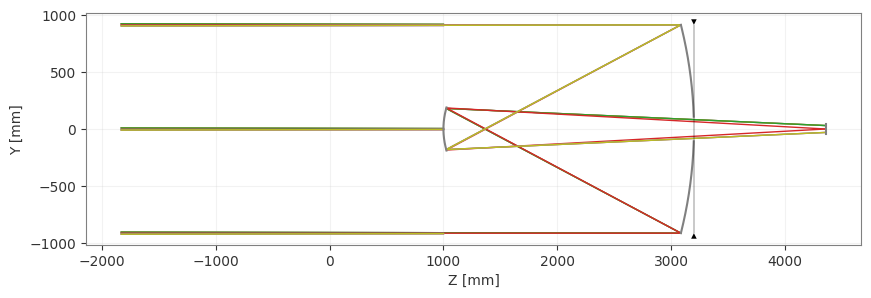

In [133]:
from optiland.fileio import load_zemax_file

lens = load_zemax_file("VATT_Model_DKim2_HChoi1.ZMX")
lens.draw()

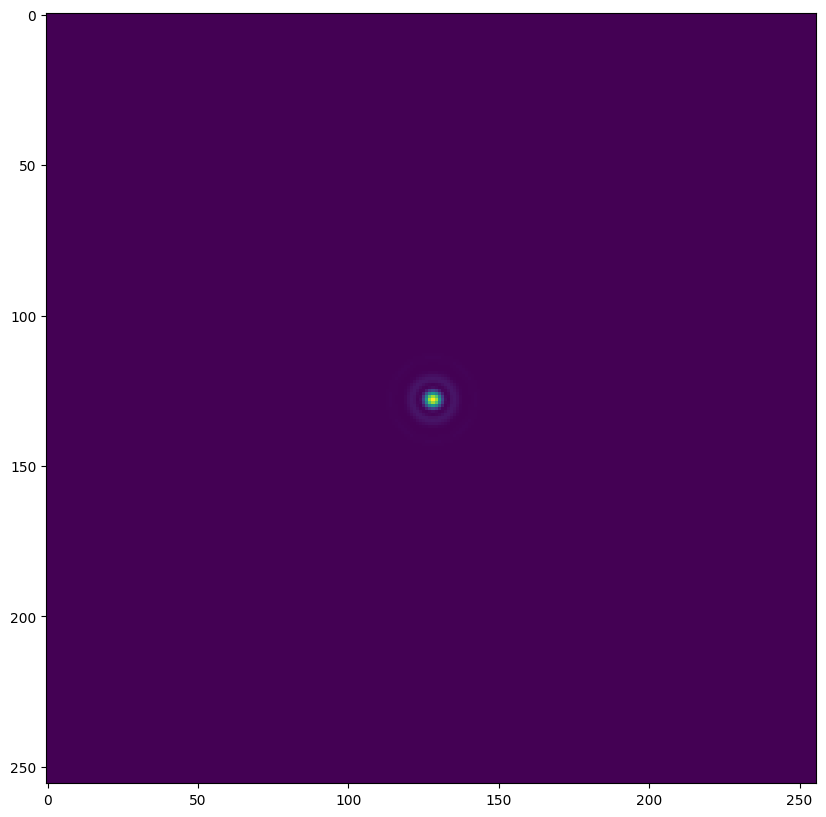

In [135]:
plt.imshow(MMDFTPSF(lens, wavelength=0.65, field=(0,0)).psf.detach().numpy())

In [101]:
from astropy.io import fits

In [102]:
image_data = fits.getdata("mc0043.fits")

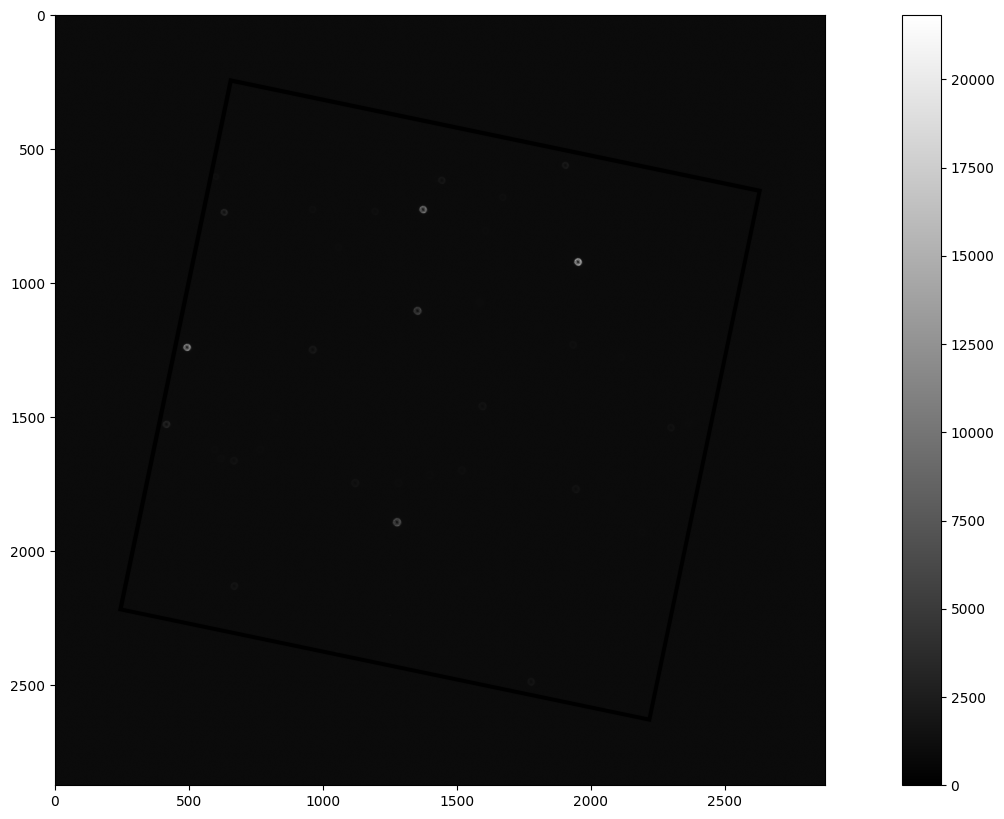

In [103]:
plt.imshow(image_data, cmap="gray")
plt.colorbar()

In [235]:
import pandas as pd

In [345]:
df = pd.read_csv('solutions_log.txt', header=None, sep=r'\s+', on_bad_lines='skip')

In [346]:
df

,0,1,2,3,4,5,6,7,8
0,Objective:,"0.0009751008807204199,",Best,X:,[,50.722326,-67.233723,1044.187046,347.44054521]
1,Objective:,"0.0009751008807204199,",Best,X:,[,50.722326,-67.233723,1044.187046,347.44054521]
2,Objective:,"0.0009751008807204199,",Best,X:,[,50.722326,-67.233723,1044.187046,347.44054521]
3,Objective:,"0.0009751008807204199,",Best,X:,[,50.722326,-67.233723,1044.187046,347.44054521]
4,Objective:,"0.0009751008807204199,",Best,X:,[,50.722326,-67.233723,1044.187046,347.44054521]
...,...,...,...,...,...,...,...,...,...
95,Objective:,"1.4217773987513561e-11,",Best,X:,[,-564.371356,59.092022,386.249742,478.14266249]
96,Objective:,"1.4217773987513561e-11,",Best,X:,[,-564.371356,59.092022,386.249742,478.14266249]
97,Objective:,"1.4217773987513561e-11,",Best,X:,[,-564.371356,59.092022,386.249742,478.14266249]
98,Objective:,"1.4217773987513561e-11,",Best,X:,[,-564.371356,59.092022,386.249742,478.14266249]


In [372]:
[float(s.strip(',')) for s in df[1].tolist()]

[0.0009751008807204199,
 0.0009751008807204199,
 0.0009751008807204199,
 0.0009751008807204199,
 0.0009751008807204199,
 6.139116290390744e-05,
 6.139116290390744e-05,
 6.139116290390744e-05,
 6.139116290390744e-05,
 6.139116290390744e-05,
 6.139116290390744e-05,
 6.139116290390744e-05,
 6.139116290390744e-05,
 6.139116290390744e-05,
 5.717063973317667e-05,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 5.2740952445616965e-06,
 4.424405173178126e-06,
 4.424405173178126e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 2.624335811786825e-06,
 1.102528448968252e-06,
 1.102528448968252e-06,
 1.1

In [396]:
import matplotlib

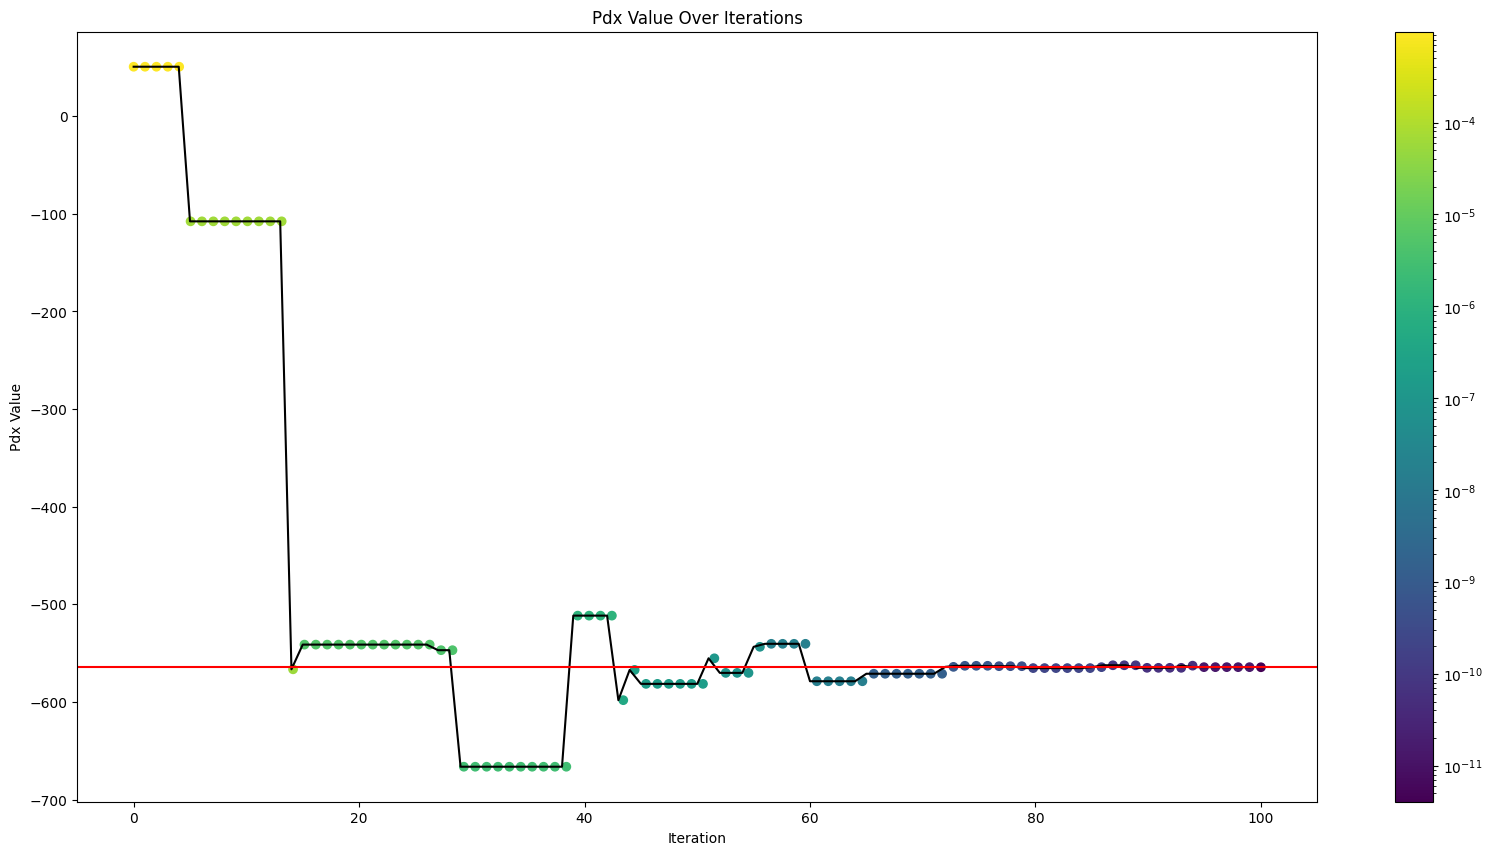

In [401]:
plt.scatter(np.linspace(0,100,100), df[5], c=[float(s.strip(',')) for s in df[1].tolist()], cmap='viridis', alpha=1, norm=matplotlib.colors.LogNorm())
plt.plot(df[5], color='k')
plt.axhline(y=-564.3626, color='r')
plt.title('Pdx Value Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Pdx Value')
plt.colorbar()

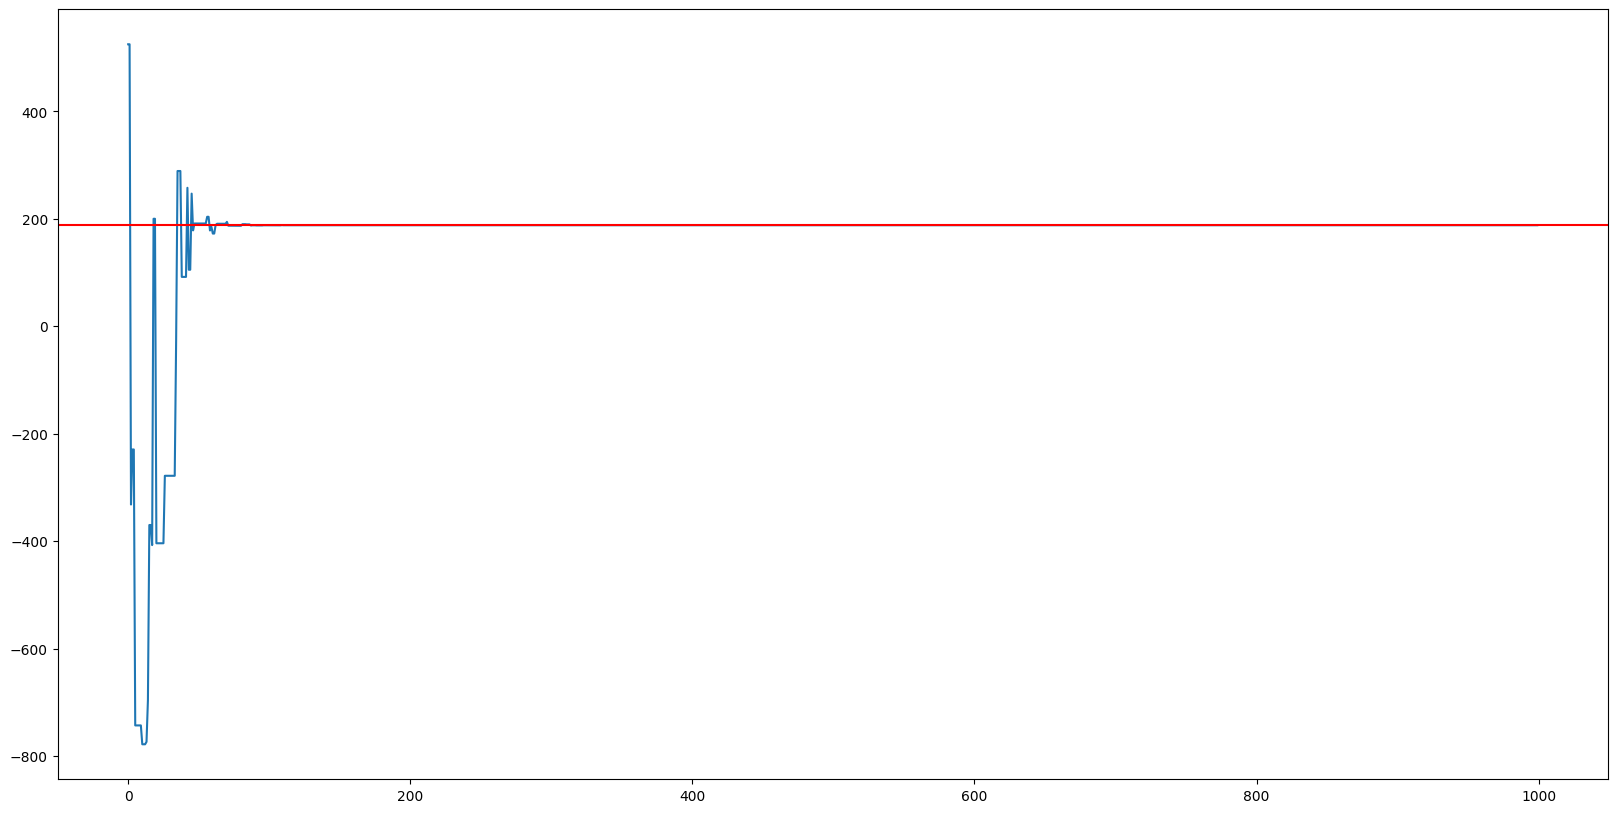

In [302]:
plt.plot(df[5])
plt.axhline(y=187.9701, color='r')